# BÀI THỰC HÀNH 2 - BÀI 2 (TRANG 37, 38)
## KHAI THÁC LUẬT KẾT HỢP VỚI TẬP DỮ LIỆU ONLINE RETAIL
- **Học viên:** Nguyễn Minh Vương
- **MSSV:** 6451071090
- **Môn học:** Khai thác dữ liệu

In [10]:
# Cài đặt thư viện nếu chạy trên Google Colab
# !pip install pandas numpy matplotlib seaborn mlxtend openpyxl gdown

import warnings
warnings.filterwarnings('ignore')

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori, association_rules, fpgrowth
%matplotlib inline

# Tự động tải thư mục dataset từ link Google Drive
if not os.path.exists("dataset") or len(os.listdir("dataset")) == 0:
    try:
        import gdown
        drive_folder_url = "https://drive.google.com/drive/folders/1rv5SiO5zFlU-cyEXul09OpCvTXrdjG1m"
        print("Đang tải dataset từ Google Drive...")
        gdown.download_folder(drive_folder_url, output="dataset", quiet=False, use_cookies=False)
        print("✅ Tải dataset thành công!")
    except Exception as e:
        print("Lưu ý: Nếu chưa có thư viện gdown, hãy chạy lệnh: !pip install gdown")

print("Nguyễn Minh Vương - 6451071090")


Nguyễn Minh Vương - 6451071090


### Câu 1: Đọc dữ liệu vào chương trình

In [11]:
print("Nguyễn Minh Vương - 6451071090")

df = pd.read_excel('dataset/Online Retail.xlsx')

print(f"Kích thước tập dữ liệu: {df.shape[0]} dòng, {df.shape[1]} cột\n")

print("--- 5 dòng đầu tiên ---")
display(df.head())

print("\n--- Cấu trúc dữ liệu (info) ---")
df.info()


Nguyễn Minh Vương - 6451071090
Kích thước tập dữ liệu: 541909 dòng, 8 cột

--- 5 dòng đầu tiên ---


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



--- Cấu trúc dữ liệu (info) ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


### Câu 2: Tiền xử lý dữ liệu: cắt khoảng trắng cột Description, xóa dòng thiếu InvoiceNo và đổi sang kiểu chuỗi

In [12]:
print("Nguyễn Minh Vương - 6451071090")

df['Description'] = df['Description'].str.strip()
df.dropna(axis=0, subset=['InvoiceNo'], inplace=True)
df['InvoiceNo'] = df['InvoiceNo'].astype('str')

print("Kiểm tra 5 dòng đầu sau khi làm sạch Description và InvoiceNo:")
display(df.head())


Nguyễn Minh Vương - 6451071090
Kiểm tra 5 dòng đầu sau khi làm sạch Description và InvoiceNo:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


### Câu 3: Xóa các hóa đơn tín dụng (hóa đơn chứa ký tự 'C' trong mã InvoiceNo)

In [13]:
print("Nguyễn Minh Vương - 6451071090")

so_dong_truoc = len(df)
df = df[~df['InvoiceNo'].str.contains('C')]
so_dong_sau = len(df)

print(f"Số dòng trước khi xóa hóa đơn tín dụng: {so_dong_truoc}")
print(f"Số dòng sau khi xóa: {so_dong_sau}")
print(f"Đã xóa {so_dong_truoc - so_dong_sau} dòng hóa đơn tín dụng.")


Nguyễn Minh Vương - 6451071090
Số dòng trước khi xóa hóa đơn tín dụng: 541909
Số dòng sau khi xóa: 532621
Đã xóa 9288 dòng hóa đơn tín dụng.


### Câu 4: Thống kê số dòng dữ liệu theo từng quốc gia

Nguyễn Minh Vương - 6451071090
Top 10 quốc gia có số lượng giao dịch nhiều nhất:
Country
United Kingdom    487622
Germany             9042
France              8408
EIRE                7894
Spain               2485
Netherlands         2363
Belgium             2031
Switzerland         1967
Portugal            1501
Australia           1185
Name: count, dtype: int64


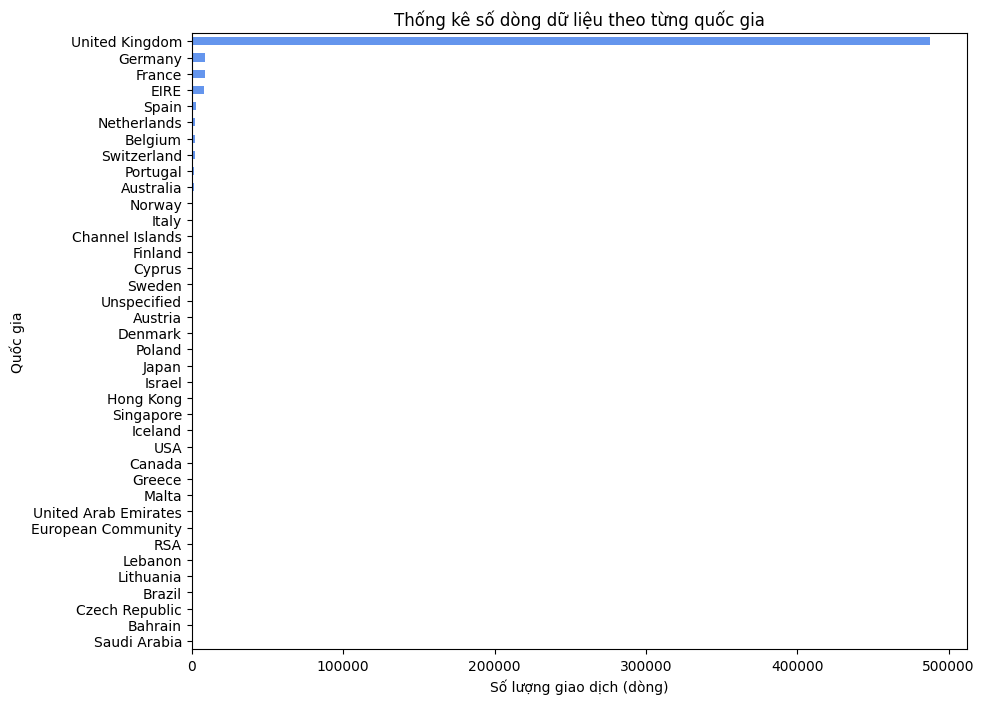

In [14]:
print("Nguyễn Minh Vương - 6451071090")

country_counts = df['Country'].value_counts()
print("Top 10 quốc gia có số lượng giao dịch nhiều nhất:")
print(country_counts.head(10))

plt.figure(figsize=(10, 8))
df['Country'].value_counts().plot(kind='barh', color='cornflowerblue')
plt.title('Thống kê số dòng dữ liệu theo từng quốc gia')
plt.xlabel('Số lượng giao dịch (dòng)')
plt.ylabel('Quốc gia')
plt.gca().invert_yaxis()
plt.show()


### Câu 5: Lấy ra dữ liệu hóa đơn từ nước Anh 'United Kingdom' và gom nhóm Quantity theo InvoiceNo và Description

In [15]:
print("Nguyễn Minh Vương - 6451071090")

grouped_uk = df[df['Country'] == "United Kingdom"].groupby(['InvoiceNo', 'Description'])['Quantity']

print("Kết quả sau khi gom nhóm dữ liệu (10 phần tử đầu):")
display(grouped_uk.sum().head(10))


Nguyễn Minh Vương - 6451071090
Kết quả sau khi gom nhóm dữ liệu (10 phần tử đầu):


InvoiceNo  Description                        
536365     CREAM CUPID HEARTS COAT HANGER          8
           GLASS STAR FROSTED T-LIGHT HOLDER       6
           KNITTED UNION FLAG HOT WATER BOTTLE     6
           RED WOOLLY HOTTIE WHITE HEART.          6
           SET 7 BABUSHKA NESTING BOXES            2
           WHITE HANGING HEART T-LIGHT HOLDER      6
           WHITE METAL LANTERN                     6
536366     HAND WARMER RED POLKA DOT               6
           HAND WARMER UNION JACK                  6
536367     ASSORTED COLOUR BIRD ORNAMENT          32
Name: Quantity, dtype: int64

### Câu 6: Chuyển đổi dữ liệu về dạng hot encoding, với mỗi dòng dữ liệu là một hóa đơn

In [16]:
print("Nguyễn Minh Vương - 6451071090")

basket = (df[df['Country'] == "United Kingdom"]
          .groupby(['InvoiceNo', 'Description'])['Quantity'].sum()
          .unstack().reset_index().fillna(0)
          .set_index('InvoiceNo'))

print(f"Kích thước ma trận giỏ hàng (basket): {basket.shape[0]} hóa đơn, {basket.shape[1]} mặt hàng")
print("Hiển thị 5 dòng và 8 cột đầu tiên của ma trận giỏ hàng:")
display(basket.iloc[:5, :8])


Nguyễn Minh Vương - 6451071090
Kích thước ma trận giỏ hàng (basket): 18667 hóa đơn, 4175 mặt hàng
Hiển thị 5 dòng và 8 cột đầu tiên của ma trận giỏ hàng:


Description,*Boombox Ipod Classic,*USB Office Mirror Ball,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 DAISY PEGS IN WOOD BOX,12 EGG HOUSE PAINTED WOOD,12 HANGING EGGS HAND PAINTED,12 IVORY ROSE PEG PLACE SETTINGS
InvoiceNo,,,,,,,,
536365,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536366,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536367,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536368,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536369,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### Câu 7: Chuyển đổi dữ liệu từ dạng hot encoding thành one-hot encoding (0 hoặc 1)

In [17]:
print("Nguyễn Minh Vương - 6451071090")

def encode_data(datapoint):
    if datapoint <= 0:
        return 0
    if datapoint >= 1:
        return 1

basket = basket.map(encode_data) if hasattr(basket, 'map') else basket.applymap(encode_data)

print("Ma trận dữ liệu One-hot encoding sau khi chuẩn hóa thành 0 và 1:")
display(basket.iloc[:5, :8])


Nguyễn Minh Vương - 6451071090
Ma trận dữ liệu One-hot encoding sau khi chuẩn hóa thành 0 và 1:


Description,*Boombox Ipod Classic,*USB Office Mirror Ball,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 DAISY PEGS IN WOOD BOX,12 EGG HOUSE PAINTED WOOD,12 HANGING EGGS HAND PAINTED,12 IVORY ROSE PEG PLACE SETTINGS
InvoiceNo,,,,,,,,
536365,0,0,0,0,0,0,0,0
536366,0,0,0,0,0,0,0,0
536367,0,0,0,0,0,0,0,0
536368,0,0,0,0,0,0,0,0
536369,0,0,0,0,0,0,0,0


### Câu 8: Xóa cột 'POSTAGE' khỏi tập dữ liệu

In [18]:
print("Nguyễn Minh Vương - 6451071090")

if 'POSTAGE' in basket.columns:
    basket.drop('POSTAGE', inplace=True, axis=1)
    print("Đã xóa thành công cột 'POSTAGE' khỏi ma trận giỏ hàng.")
else:
    print("Cột 'POSTAGE' không tồn tại trong tập dữ liệu giỏ hàng.")


Nguyễn Minh Vương - 6451071090
Đã xóa thành công cột 'POSTAGE' khỏi ma trận giỏ hàng.


### Câu 9: Tìm tập phổ biến bằng thuật toán Apriori với min_sup = 3%

In [19]:
print("Nguyễn Minh Vương - 6451071090")

itemsets_apriori = apriori(basket, min_support=0.03, use_colnames=True)

print(f"Tổng số tập mục phổ biến tìm được bằng Apriori: {len(itemsets_apriori)}")
print("\n10 phần tử đầu tiên trong tập phổ biến:")
display(itemsets_apriori.head(10))


Nguyễn Minh Vương - 6451071090
Tổng số tập mục phổ biến tìm được bằng Apriori: 131

10 phần tử đầu tiên trong tập phổ biến:


,support,itemsets
0,0.045803,(6 RIBBONS RUSTIC CHARM)
1,0.031124,(60 CAKE CASES VINTAGE CHRISTMAS)
2,0.040339,(60 TEATIME FAIRY CAKE CASES)
3,0.046928,(ALARM CLOCK BAKELIKE GREEN)
4,0.035142,(ALARM CLOCK BAKELIKE PINK)
5,0.049821,(ALARM CLOCK BAKELIKE RED)
6,0.036214,(ANTIQUE SILVER T-LIGHT GLASS)
7,0.073445,(ASSORTED COLOUR BIRD ORNAMENT)
8,0.042267,(BAKING SET 9 PIECE RETROSPOT)
9,0.035089,(BATHROOM METAL SIGN)


### Câu 10: Tạo luật kết hợp với min_conf = 50% và in ra các luật này

In [20]:
print("Nguyễn Minh Vương - 6451071090")

rules = association_rules(itemsets_apriori, metric="confidence", min_threshold=0.5)

print(f"Tổng số luật kết hợp tìm được: {len(rules)}\n")

rules_print = rules.copy()
rules_print['antecedents'] = rules_print['antecedents'].apply(lambda x: ', '.join(list(x)))
rules_print['consequents'] = rules_print['consequents'].apply(lambda x: ', '.join(list(x)))

for i in range(len(rules_print)):
    print(f"Luật {i+1}: {rules_print.loc[i, 'antecedents']}  ==>  {rules_print.loc[i, 'consequents']}")
    print(f"         Support: {rules_print.loc[i, 'support']:.4f} | Confidence: {rules_print.loc[i, 'confidence']:.4f} | Lift: {rules_print.loc[i, 'lift']:.4f}\n")


Nguyễn Minh Vương - 6451071090
Tổng số luật kết hợp tìm được: 10

Luật 1: ALARM CLOCK BAKELIKE RED  ==>  ALARM CLOCK BAKELIKE GREEN
         Support: 0.0302 | Confidence: 0.6054 | Lift: 12.9002

Luật 2: ALARM CLOCK BAKELIKE GREEN  ==>  ALARM CLOCK BAKELIKE RED
         Support: 0.0302 | Confidence: 0.6427 | Lift: 12.9002

Luật 3: GREEN REGENCY TEACUP AND SAUCER  ==>  PINK REGENCY TEACUP AND SAUCER
         Support: 0.0309 | Confidence: 0.6178 | Lift: 16.4039

Luật 4: PINK REGENCY TEACUP AND SAUCER  ==>  GREEN REGENCY TEACUP AND SAUCER
         Support: 0.0309 | Confidence: 0.8208 | Lift: 16.4039

Luật 5: ROSES REGENCY TEACUP AND SAUCER  ==>  GREEN REGENCY TEACUP AND SAUCER
         Support: 0.0376 | Confidence: 0.7325 | Lift: 14.6398

Luật 6: GREEN REGENCY TEACUP AND SAUCER  ==>  ROSES REGENCY TEACUP AND SAUCER
         Support: 0.0376 | Confidence: 0.7505 | Lift: 14.6398

Luật 7: JUMBO  BAG BAROQUE BLACK WHITE  ==>  JUMBO BAG RED RETROSPOT
         Support: 0.0305 | Confidence: 0.6264

### Câu 11: Biểu diễn độ tin cậy và độ hỗ trợ của tập luật lên đồ thị phân tán (scatter plot)

Nguyễn Minh Vương - 6451071090


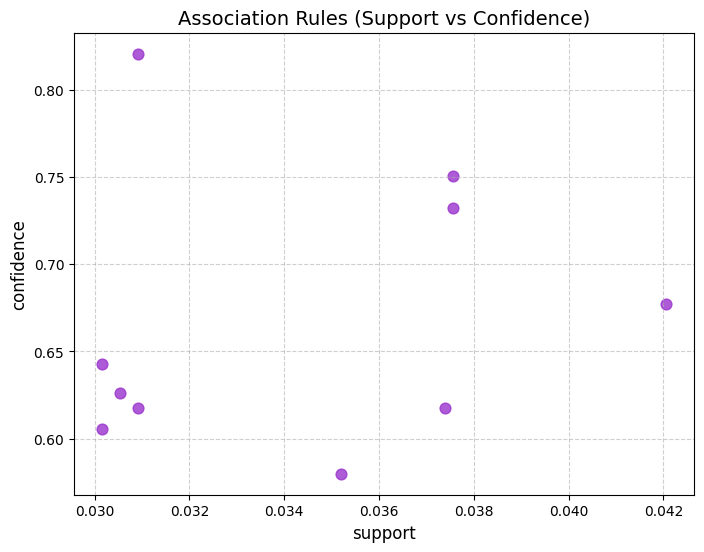

In [21]:
print("Nguyễn Minh Vương - 6451071090")

plt.figure(figsize=(8, 6))
plt.title('Association Rules (Support vs Confidence)', fontsize=14)
plt.xlabel('Support', fontsize=12)
plt.ylabel('Confidence', fontsize=12)

sns.regplot(x=rules['support'], y=rules['confidence'], fit_reg=False, color='darkorchid', scatter_kws={'s': 60})
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


### Câu 12: Tìm tập phổ biến và luật kết hợp bằng thuật toán FP-Growth với min_sup = 3%, min_conf = 50% và so sánh với Apriori

In [22]:
print("Nguyễn Minh Vương - 6451071090")

# Tìm tập phổ biến bằng thuật toán FP-Growth
itemsets_fpgrowth = fpgrowth(basket, min_support=0.03, use_colnames=True)
print(f"Số lượng tập phổ biến bằng FP-Growth: {len(itemsets_fpgrowth)}")
print(f"Số lượng tập phổ biến bằng Apriori:   {len(itemsets_apriori)}")

# Sinh luật kết hợp từ kết quả FP-Growth
rules_fpgrowth = association_rules(itemsets_fpgrowth, metric="confidence", min_threshold=0.5)
print(f"Số lượng luật kết hợp từ FP-Growth:    {len(rules_fpgrowth)}")
print(f"Số lượng luật kết hợp từ Apriori:      {len(rules)}")

print("\n--- NHẬN XÉT SO SÁNH HAI THUẬT TOÁN ---")
print("1. Số lượng tập phổ biến và tập luật kết hợp tìm được từ cả hai thuật toán là hoàn toàn trùng khớp.")
print("2. Về thuật toán:")
print("   - Apriori phải sinh các tập ứng viên (candidate generation) và quét qua cơ sở dữ liệu nhiều lần.")
print("   - FP-Growth nén cơ sở dữ liệu thành cấu trúc cây FP-tree và khai thác đệ quy, chỉ quét CSDL 2 lần, do đó đạt hiệu năng cao hơn rất nhiều.")


Nguyễn Minh Vương - 6451071090
Số lượng tập phổ biến bằng FP-Growth: 131
Số lượng tập phổ biến bằng Apriori:   131
Số lượng luật kết hợp từ FP-Growth:    10
Số lượng luật kết hợp từ Apriori:      10

--- NHẬN XÉT SO SÁNH HAI THUẬT TOÁN ---
1. Số lượng tập phổ biến và tập luật kết hợp tìm được từ cả hai thuật toán là hoàn toàn trùng khớp.
2. Về thuật toán:
   - Apriori phải sinh các tập ứng viên (candidate generation) và quét qua cơ sở dữ liệu nhiều lần.
   - FP-Growth nén cơ sở dữ liệu thành cấu trúc cây FP-tree và khai thác đệ quy, chỉ quét CSDL 2 lần, do đó đạt hiệu năng cao hơn rất nhiều.
